# Assignment 3 — Explainable Wine Quality Inference
Reproducible pipeline. Run `python src/train.py` first (writes `submissions/` and `src/_oof.pkl`), then this notebook for analysis and report figures.

* `src/common.py` — data, QWK, thresholds, CV · `src/concept_model.py` — concept-bottleneck model · `src/models.py` — model configs

In [1]:
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, shap, lightgbm as lgb
sys.path.insert(0,'src')
from common import *; from models import MODELS, LGB; from concept_model import ConceptBottleneck
tr, te, y = load(); X, Xte = tr[RAW], te[RAW]
R = pd.read_pickle('src/_oof.pkl'); OOF, TE, SEEDS = R['oof'], R['te'], R['seeds']
plt.rcParams['figure.dpi'] = 110

## Q1 — Preliminary analysis

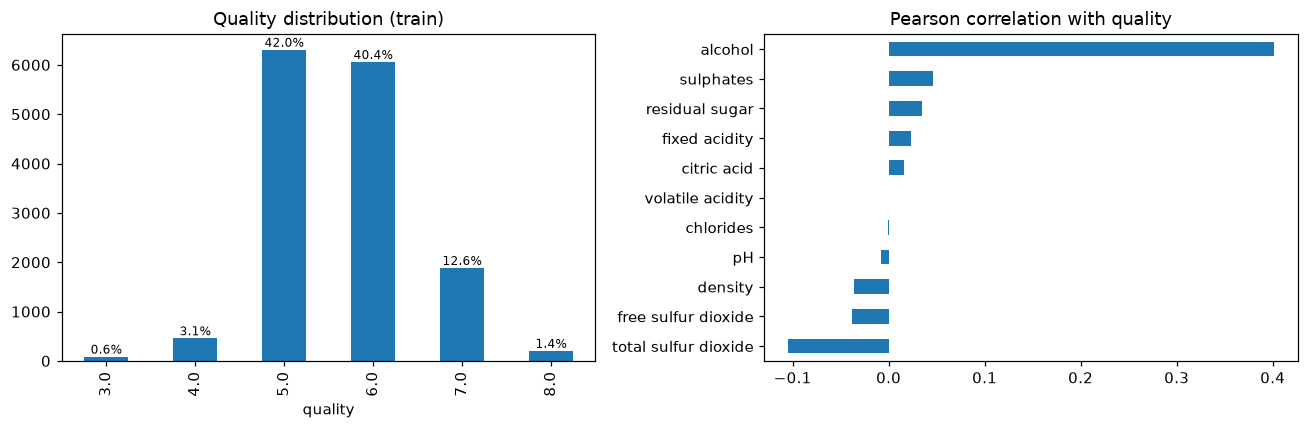

In [2]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
vc=tr.quality.value_counts().sort_index(); vc.plot.bar(ax=ax[0],title='Quality distribution (train)')
for i,v in enumerate(vc): ax[0].text(i,v,f'{v/len(tr):.1%}',ha='center',va='bottom',fontsize=8)
tr[RAW+['quality']].corr()['quality'].drop('quality').sort_values().plot.barh(ax=ax[1],title='Pearson correlation with quality')
plt.tight_layout(); plt.savefig('figures/q1_target_corr.png',dpi=200)

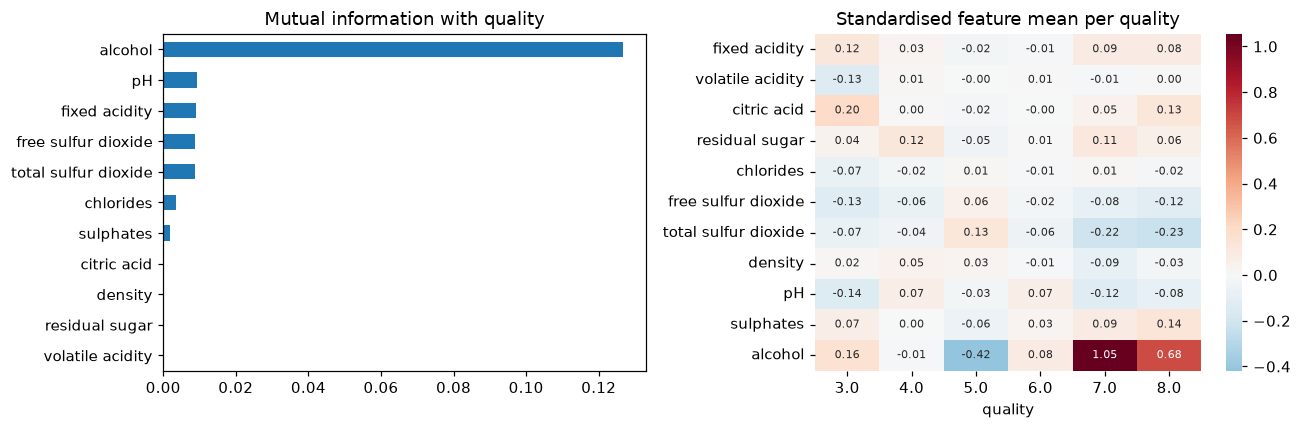

In [3]:
# Non-linear dependence: mutual information + quality-binned means
from sklearn.feature_selection import mutual_info_regression
mi=pd.Series(mutual_info_regression(X,y,random_state=SEED),index=RAW).sort_values()
fig,ax=plt.subplots(1,2,figsize=(12,4)); mi.plot.barh(ax=ax[0],title='Mutual information with quality')
z=(tr.groupby('quality')[RAW].mean()-X.mean())/X.std()
sns.heatmap(z.T,cmap='RdBu_r',center=0,ax=ax[1],annot=True,fmt='.2f',annot_kws={'size':7}); ax[1].set_title('Standardised feature mean per quality')
plt.tight_layout(); plt.savefig('figures/q1_mi_heatmap.png',dpi=200)

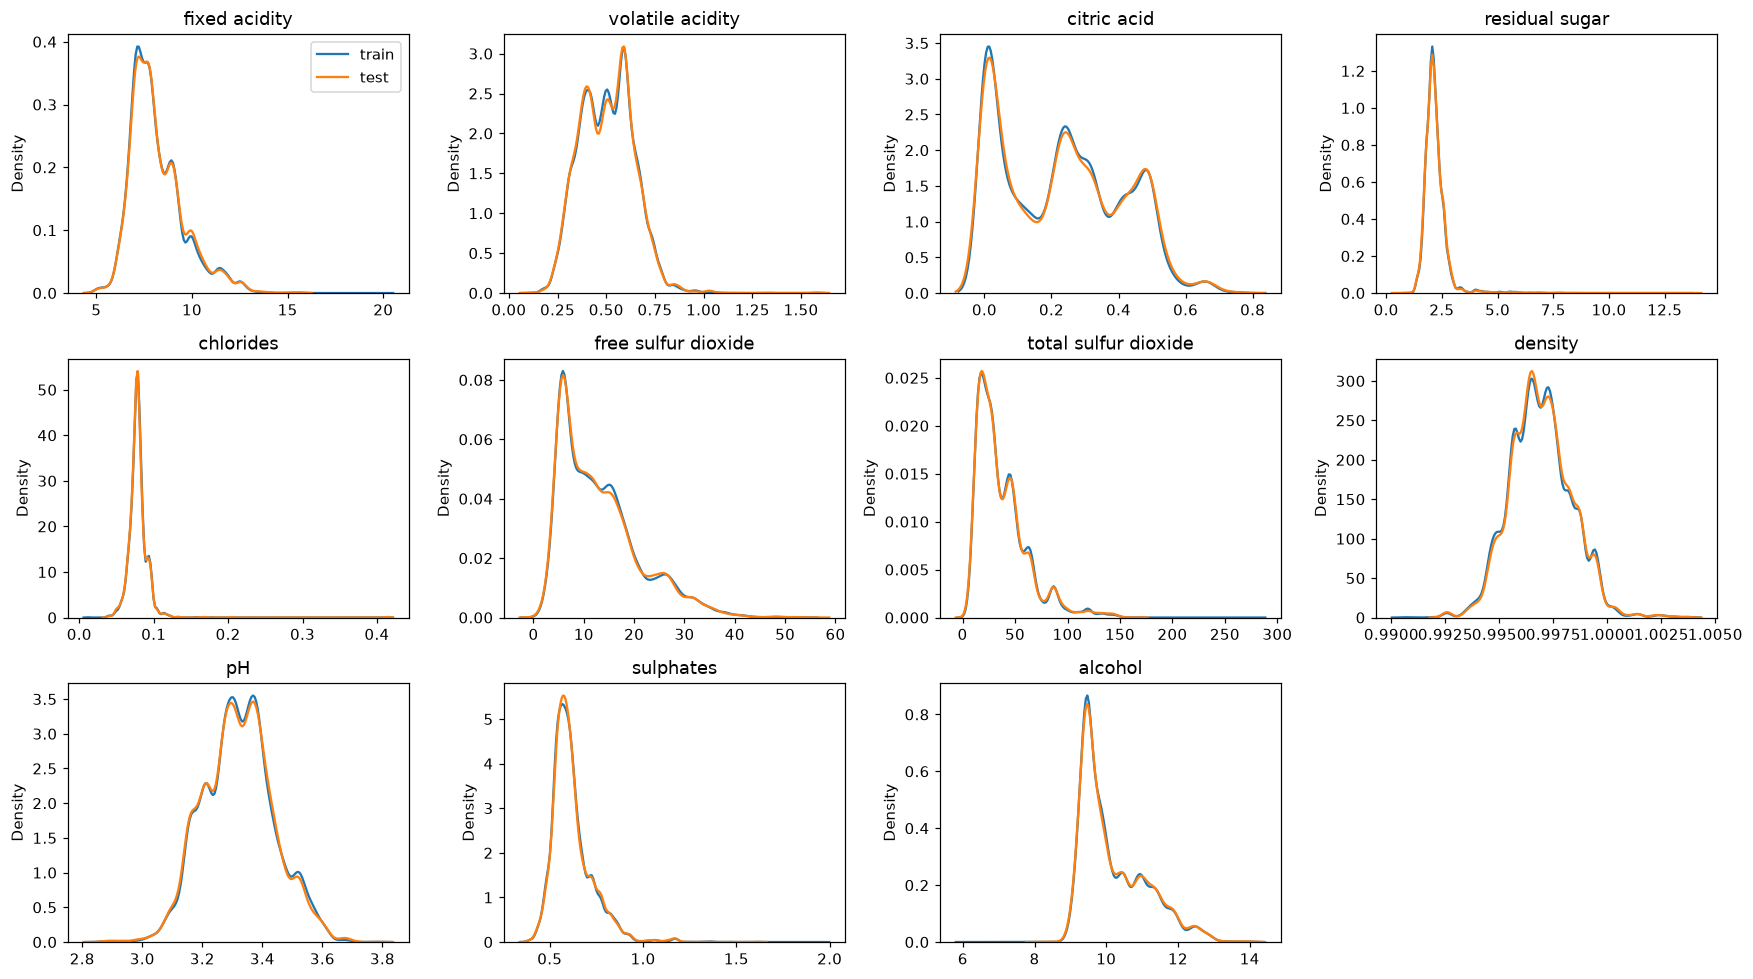

In [4]:
fig,axes=plt.subplots(3,4,figsize=(16,9))
for f,a in zip(RAW,axes.ravel()):
    sns.kdeplot(tr[f],ax=a,label='train'); sns.kdeplot(te[f],ax=a,label='test'); a.set_title(f); a.set_xlabel('')
axes.ravel()[0].legend(); axes.ravel()[-1].axis('off'); plt.tight_layout(); plt.savefig('figures/q1_train_test_shift.png',dpi=150)

In [5]:
# Feature engineering test (domain features) — result: no gain, so the final model uses raw features
Xf, Xf_te = add_features(tr), add_features(te)
for name,(A,B) in {'raw':(X,Xte),'+FE':(Xf,Xf_te)}.items():
    o,_,_=cv_reg(lambda:lgb.LGBMRegressor(**LGB,random_state=SEED),A,y,B); print(f'LGBM {name}: CV QWK {score(o,y)[0]:.4f}')

LGBM raw: CV QWK 0.4169


LGBM +FE: CV QWK 0.4161


## Q3 — Ablation (CV QWK, mean ± std over 3 CV seeds × 5 folds)

In [6]:
def cv_stats(members, thresholds=True):
    s=[]
    for i in range(len(SEEDS)):
        o=np.mean([OOF[m][i] for m in members],0)
        s.append(score(o,y)[0] if thresholds else qwk(y,np.clip(np.rint(o),3,8).astype(int)))
    return f'{np.mean(s):.4f} ± {np.std(s):.4f}'
rows={'Ridge (linear baseline), rounding':cv_stats(['Ridge'],False),
      'Ridge + thresholds':cv_stats(['Ridge']),
      'LGBM, rounding':cv_stats(['LGBM'],False),
      'LGBM + thresholds':cv_stats(['LGBM']),
      'EBM + thresholds':cv_stats(['EBM']),
      'CBM, rounding':cv_stats(['CBM'],False),
      'CBM + thresholds  [final intrinsic]':cv_stats(['CBM']),
      'CBM + EBM + LGBM + thresholds  [final blend]':cv_stats(['CBM','EBM','LGBM'])}
abl=pd.Series(rows,name='CV QWK').to_frame(); abl

,CV QWK
"Ridge (linear baseline), rounding",0.2823 ± 0.0008
Ridge + thresholds,0.4065 ± 0.0007
"LGBM, rounding",0.3329 ± 0.0011
LGBM + thresholds,0.4164 ± 0.0007
EBM + thresholds,0.4137 ± 0.0019
"CBM, rounding",0.3278 ± 0.0007
CBM + thresholds [final intrinsic],0.4165 ± 0.0005
CBM + EBM + LGBM + thresholds [final blend],0.4178 ± 0.0006


In [7]:
# CBM ablation: drop one concept at a time (does each concept help?)
res={}
for drop in [None]+list(CONCEPTS):
    cc={k:v for k,v in CONCEPTS.items() if k!=drop}
    o,_,_=cv_reg(lambda:ConceptBottleneck(concepts=cc),X,y,Xte); res['full' if drop is None else f'- {drop}']=score(o,y)[0]
pd.Series(res,name='CV QWK').round(4).to_frame()

,CV QWK
full,0.4171
- acidity,0.4172
- preservation,0.4161
- body,0.1047
- salinity,0.4170


## Q4 — Explainability
### Intrinsic: concept-bottleneck model (prediction = Σ_k w_k·c_k(x) + b)

weights {'acidity': 0.0, 'preservation': 0.272, 'body': 0.968, 'salinity': 0.0}  intercept -1.354


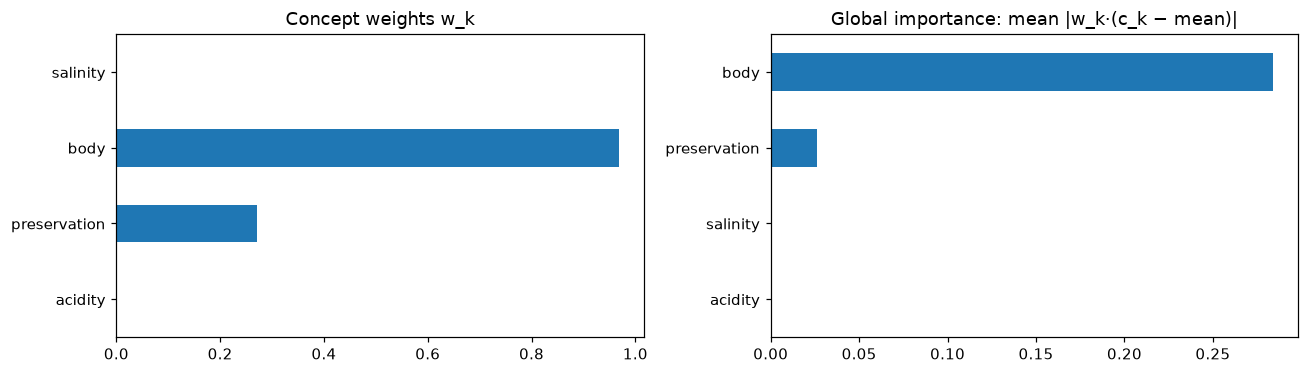

In [8]:
cbm=ConceptBottleneck().fit(X,y)
w=pd.Series(cbm.f.coef_,index=CONCEPTS.keys()); print('weights',w.round(3).to_dict(),' intercept',round(cbm.f.intercept_,3))
contrib=pd.DataFrame(cbm.contributions(X),columns=CONCEPTS.keys())
imp=(contrib-contrib.mean()).abs().mean().sort_values()
fig,ax=plt.subplots(1,2,figsize=(12,3.5)); w.plot.barh(ax=ax[0],title='Concept weights w_k')
imp.plot.barh(ax=ax[1],title='Global importance: mean |w_k·(c_k − mean)|'); plt.tight_layout(); plt.savefig('figures/q4_cbm_global.png',dpi=200)

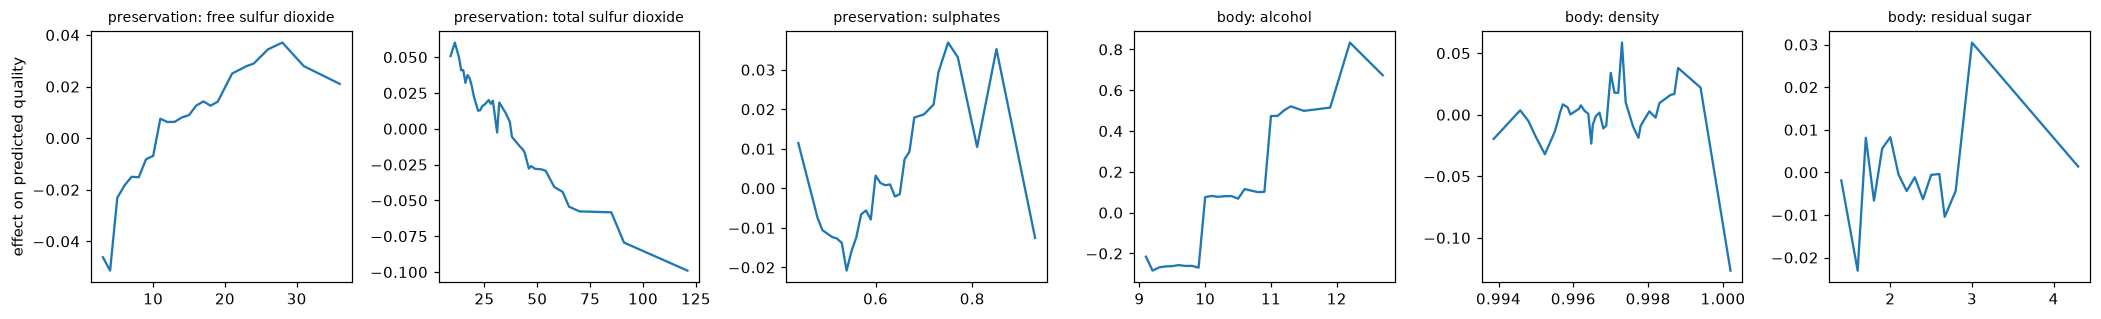

In [9]:
# How each active concept score depends on its features (1-D partial dependence of w_k * g_k)
act=[(k,cols,g,wk) for (k,cols),g,wk in zip(CONCEPTS.items(),cbm.g,cbm.f.coef_) if wk>0]
n=sum(len(cols) for _,cols,_,_ in act); fig,axes=plt.subplots(1,n,figsize=(3.2*n,3)); j=0
base=X.sample(2000,random_state=0)
for k,cols,g,wk in act:
    for c in cols:
        grid=np.quantile(X[c],np.linspace(.01,.99,40))
        pd_=np.array([wk*g.predict(base[cols].assign(**{c:v})).mean() for v in grid])
        axes[j].plot(grid,pd_-pd_.mean()); axes[j].set_title(f'{k}: {c}',fontsize=9); j+=1
axes[0].set_ylabel('effect on predicted quality'); plt.tight_layout(); plt.savefig('figures/q4_cbm_pdp.png',dpi=150)

high (true 8) 77 {'fixed acidity': 8.3, 'volatile acidity': 0.31, 'citric acid': 0.31, 'residual sugar': 2.2, 'chlorides': 0.077, 'free sulfur dioxide': 9.0, 'total sulfur dioxide': 22.0, 'density': 0.996, 'pH': 3.38, 'sulphates': 0.57, 'alcohol': 11.7}
low (true 4) 69 {'fixed acidity': 7.5, 'volatile acidity': 0.57, 'citric acid': 0.0, 'residual sugar': 2.0, 'chlorides': 0.082, 'free sulfur dioxide': 28.0, 'total sulfur dioxide': 53.0, 'density': 0.996, 'pH': 3.47, 'sulphates': 0.73, 'alcohol': 9.2}


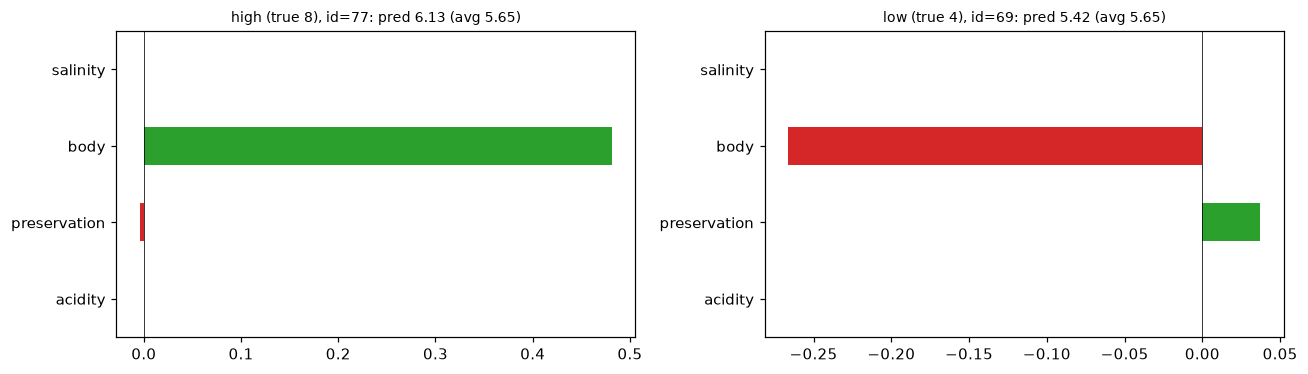

In [10]:
# Case study: a high-quality and a low-quality wine
oof_cbm=OOF['CBM'][0]; t=fit_t(oof_cbm,y)
cases={'high (true 8)':int(np.where((y==8)&(apply_t(oof_cbm,t)>=7))[0][0]), 'low (true 4)':int(np.where((y==4)&(apply_t(oof_cbm,t)==5))[0][0])}
fig,axes=plt.subplots(1,2,figsize=(12,3.5))
for a,(lab,i) in zip(axes,cases.items()):
    d=contrib.iloc[i]-contrib.mean()
    d.plot.barh(ax=a,color=['tab:green' if v>0 else 'tab:red' for v in d])
    a.set_title(f'{lab}, id={i}: pred {cbm.predict(X.iloc[[i]])[0]:.2f} (avg {cbm.predict(X).mean():.2f})',fontsize=9); a.axvline(0,c='k',lw=.5)
    print(lab, i, X.iloc[i].round(3).to_dict())
plt.tight_layout(); plt.savefig('figures/q4_case_study_cbm.png',dpi=200)

### Post-hoc: SHAP on LightGBM (sanity check that the intrinsic explanation agrees)

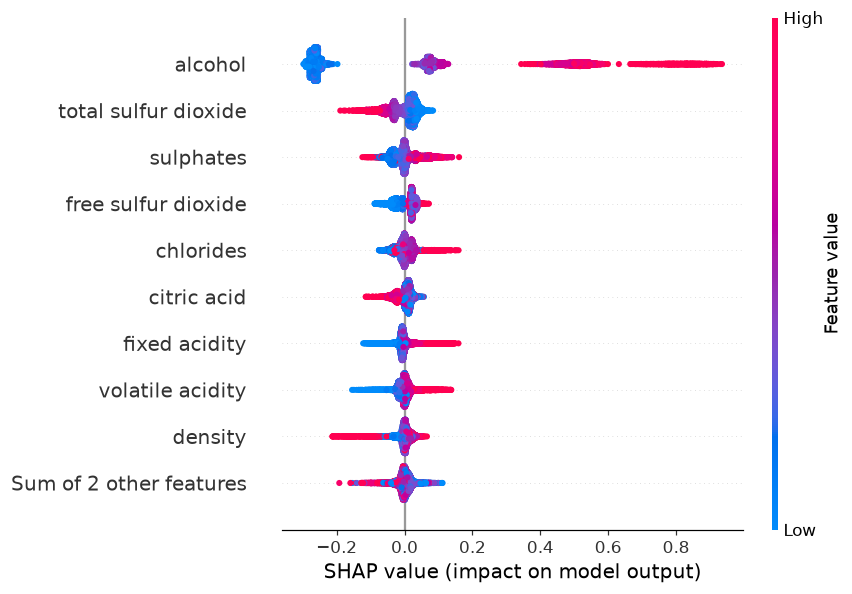

,"SHAP (LGBM, grouped)",CBM importance
acidity,0.083,0.000
body,0.764,0.916
preservation,0.108,0.084
salinity,0.044,0.000


In [11]:
lg=lgb.LGBMRegressor(**LGB,random_state=SEED).fit(X,y); sv=shap.TreeExplainer(lg)(X)
shap.plots.beeswarm(sv,show=False); plt.tight_layout(); plt.savefig('figures/q4_shap_beeswarm.png',dpi=200); plt.show()
grp=pd.Series({k:np.abs(sv.values[:,[RAW.index(c) for c in cols]].sum(1)).mean() for k,cols in CONCEPTS.items()})
pd.DataFrame({'SHAP (LGBM, grouped)':grp/grp.sum(),'CBM importance':imp/imp.sum()}).round(3)

In [12]:
i=cases['high (true 8)']; shap.plots.waterfall(sv[i],show=False); plt.tight_layout(); plt.savefig('figures/q4_case_study_shap.png',dpi=200)